# 03 · Primary analysis – COG allocation versus growth rate

This notebook answers the project question directly.

**Quantity.** For every sample, protein mass fractions are summed within each COG functional category. An undetected protein contributes zero mass, which is the correct value for a mass balance, so **nothing is imputed** and no protein is filtered out.

**Unit of analysis.** The growth condition. Replicate runs are averaged first.

**Combining the studies.** All conditions of all four datasets enter one model and one shared slope per category; each batch only keeps its own baseline. Section 3 shows the combined proteome condition by condition.

**Model, per category.** `fraction = intercept(dataset) + slope × growth rate`. Each dataset has its own intercept, which absorbs additive platform offsets; the slope is shared and is estimated only from within-dataset contrasts. The fraction is analysed on its linear scale because bacterial growth laws are linear in mass fraction.

**Inference.** With a few dozen conditions, distributional assumptions are avoided:

| quantity | method |
|---|---|
| p-value | growth rates permuted **within** each dataset |
| 95 % interval | conditions bootstrapped **within** each dataset (run in parallel, seeded) |
| multiple testing | Benjamini–Hochberg across categories |
| stability | slope recomputed leaving each dataset out (jackknife over studies) |

In [1]:
import sys
from pathlib import Path

# repository root = first parent folder that contains config.yml (no machine-specific paths)
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "config.yml").exists())
sys.path.insert(0, str(ROOT / "src"))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from proteome_alloc import config, ingest, annotation, scope, allocation, asca, predict, plots, combined, proteomap
from proteome_alloc.ingest import GROWTH

cfg = config.load_config()
pd.set_option("display.max_columns", 40, "display.width", 220, "display.max_colwidth", 60)
print("Repository root :", cfg.root)
print("Config file     :", cfg.config_file.name, "| master seed:", cfg["seed"])

Repository root : C:\Users\arlin\OneDrive\Documentos\proteome_allocation\proteome_allocation
Config file     : config.yml | master seed: 20261011


In [2]:
X, obs, var = scope.load_scoped(cfg)
annotation_table = annotation.load_annotation(cfg)
labels = annotation.category_labels(cfg)

in_scope = obs.index[obs["In_Scope"]]
F, coverage = allocation.cog_fractions(X.loc[in_scope], annotation_table, cfg)
print("COG fraction matrix (runs x categories):", F.shape)
display(coverage.groupby(obs.loc[in_scope, "Dataset_Source"]).agg(["min", "median", "max"]).round(3).T)

COG fraction matrix (runs x categories): (39, 27)


Dataset_Source                                   mori_2021  schmidt_2016   wu_2023  zhu_2025
mass_fraction_sum_before_renormalisation min         1.000         0.996     1.000     0.998
                                         median      1.000         0.996     1.000     0.999
                                         max         1.000         0.996     1.000     0.999
n_proteins_detected                      min      1918.000      1986.000  1579.000  1160.000
                                         median   2002.000      1986.000  1792.000  1765.000
                                         max      2105.000      1986.000  1862.000  1776.000
mass_fraction_with_COG                   min         0.959         0.991     0.977     0.980
                                         median      0.968         0.991     0.982     0.984
                                         max         0.984         0.991     0.989     0.986
n_detected_without_COG                   min        93.000        93.000    61.000    28.000
                                         median    100.000        93.000    76.000    63.000
                                         max       107.000        93.000    83.000    64.000

## 1 · How much of the proteome does the annotation cover?

A category fraction is only interpretable if most of the protein mass has a category. The right-hand panel shows the share of each sample's mass that falls in a COG category; the remainder is kept as its own group (`-`) so that the fractions still describe the whole proteome.

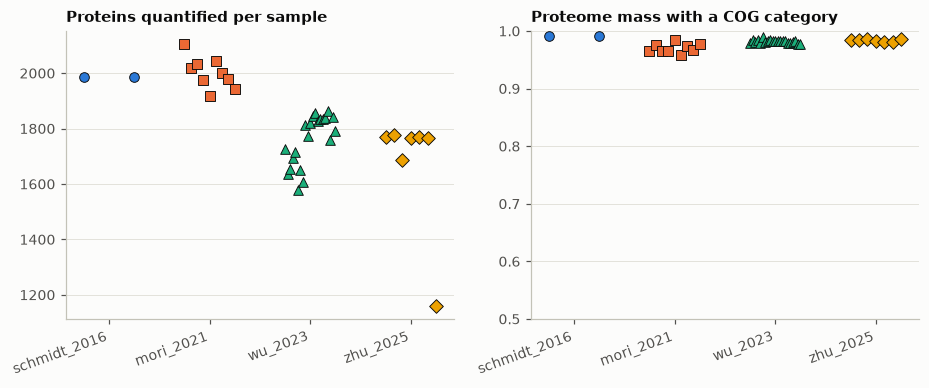

In [3]:
fig = plots.plot_coverage(coverage, obs, cfg.figures / "03_annotation_coverage.png")
plt.show()

## 2 · From runs to conditions

In [4]:
Fc, info = allocation.aggregate_conditions(F, obs.loc[in_scope], cfg)
print(f"{len(F)} runs -> {len(Fc)} conditions")
display(info)

39 runs -> 27 conditions


,n_replicates,Specific_Growth_Rate_h-1,growth_sd,Dataset_Source,samples
Condition,,,,,
schmidt_2016|LB,1,2.300000,NaN,schmidt_2016,LB
schmidt_2016|Glucose_Minimal,1,1.030000,NaN,schmidt_2016,Glucose
mori_2021|Acetate,1,0.501070,NaN,mori_2021,Lib-06
mori_2021|Kanamycin,1,0.742658,NaN,mori_2021,Lib-07
mori_2021|Poor N,1,0.240398,NaN,mori_2021,Lib-15
mori_2021|Carbon 46,1,0.904105,NaN,mori_2021,Lib-24
mori_2021|Carbon 37,1,1.124022,NaN,mori_2021,Lib-26
mori_2021|Carbon 85,1,0.489280,NaN,mori_2021,Lib-27
mori_2021|Carbon 50,1,0.831777,NaN,mori_2021,Lib-28


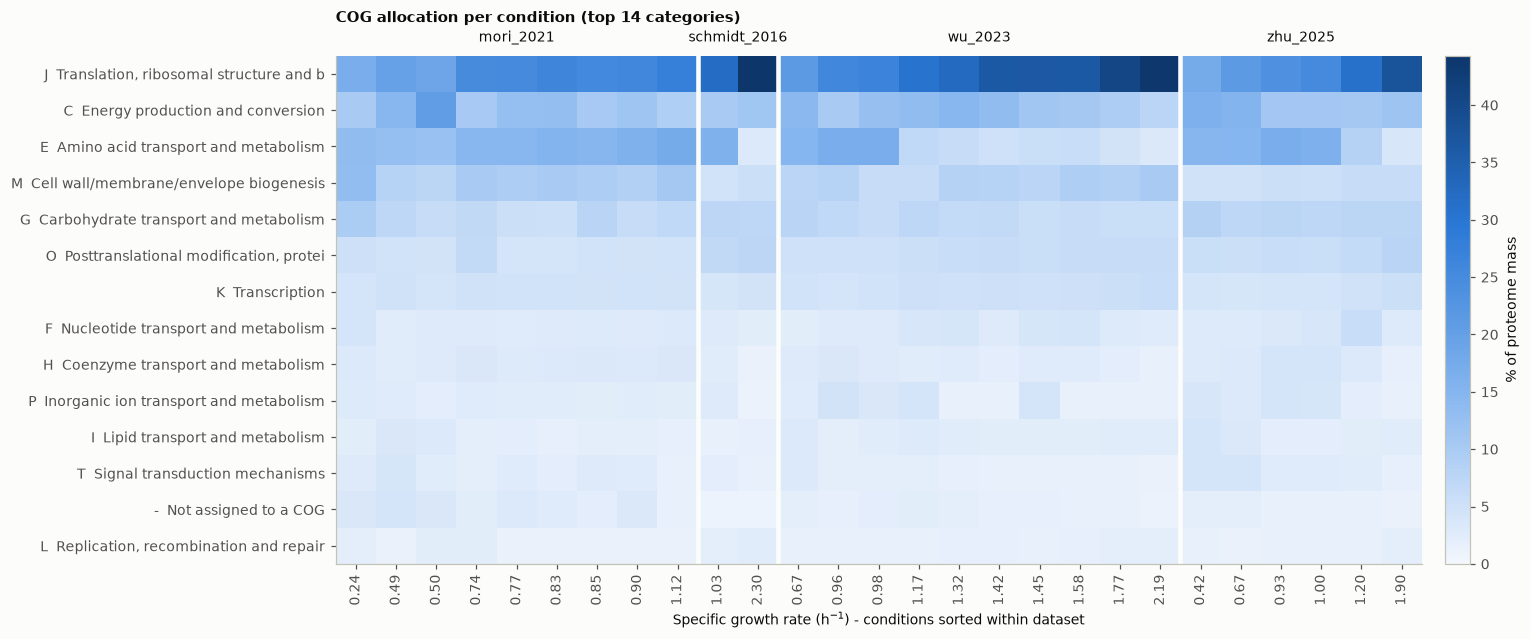

In [5]:
fig = plots.plot_composition(Fc, info, labels, cfg.figures / "03_cog_composition_heatmap.png")
plt.show()

A heat map on a single-hue scale is used because the values are magnitudes (percent of proteome mass). Conditions are sorted by growth rate inside each dataset, so a growth-dependent category appears as a left-to-right gradient that repeats in every block; a difference *between* blocks that does not follow growth rate is a dataset effect.

## 3 · All datasets combined: how the proteome changes from condition to condition

The four studies are now put on **one axis**. Each batch is measured on its own platform, so its values carry an offset; that offset is estimated together with the growth effect (`fraction = offset(batch) + slope × growth rate`) and subtracted, keeping the growth term and the condition-specific residual. Fitting both jointly matters: a study that measured only fast conditions keeps its fast position instead of being pulled to the centre.

These adjusted values are for display; the statistics in section 4 are fitted on the unadjusted fractions with the batch inside the model, so nothing is used twice.

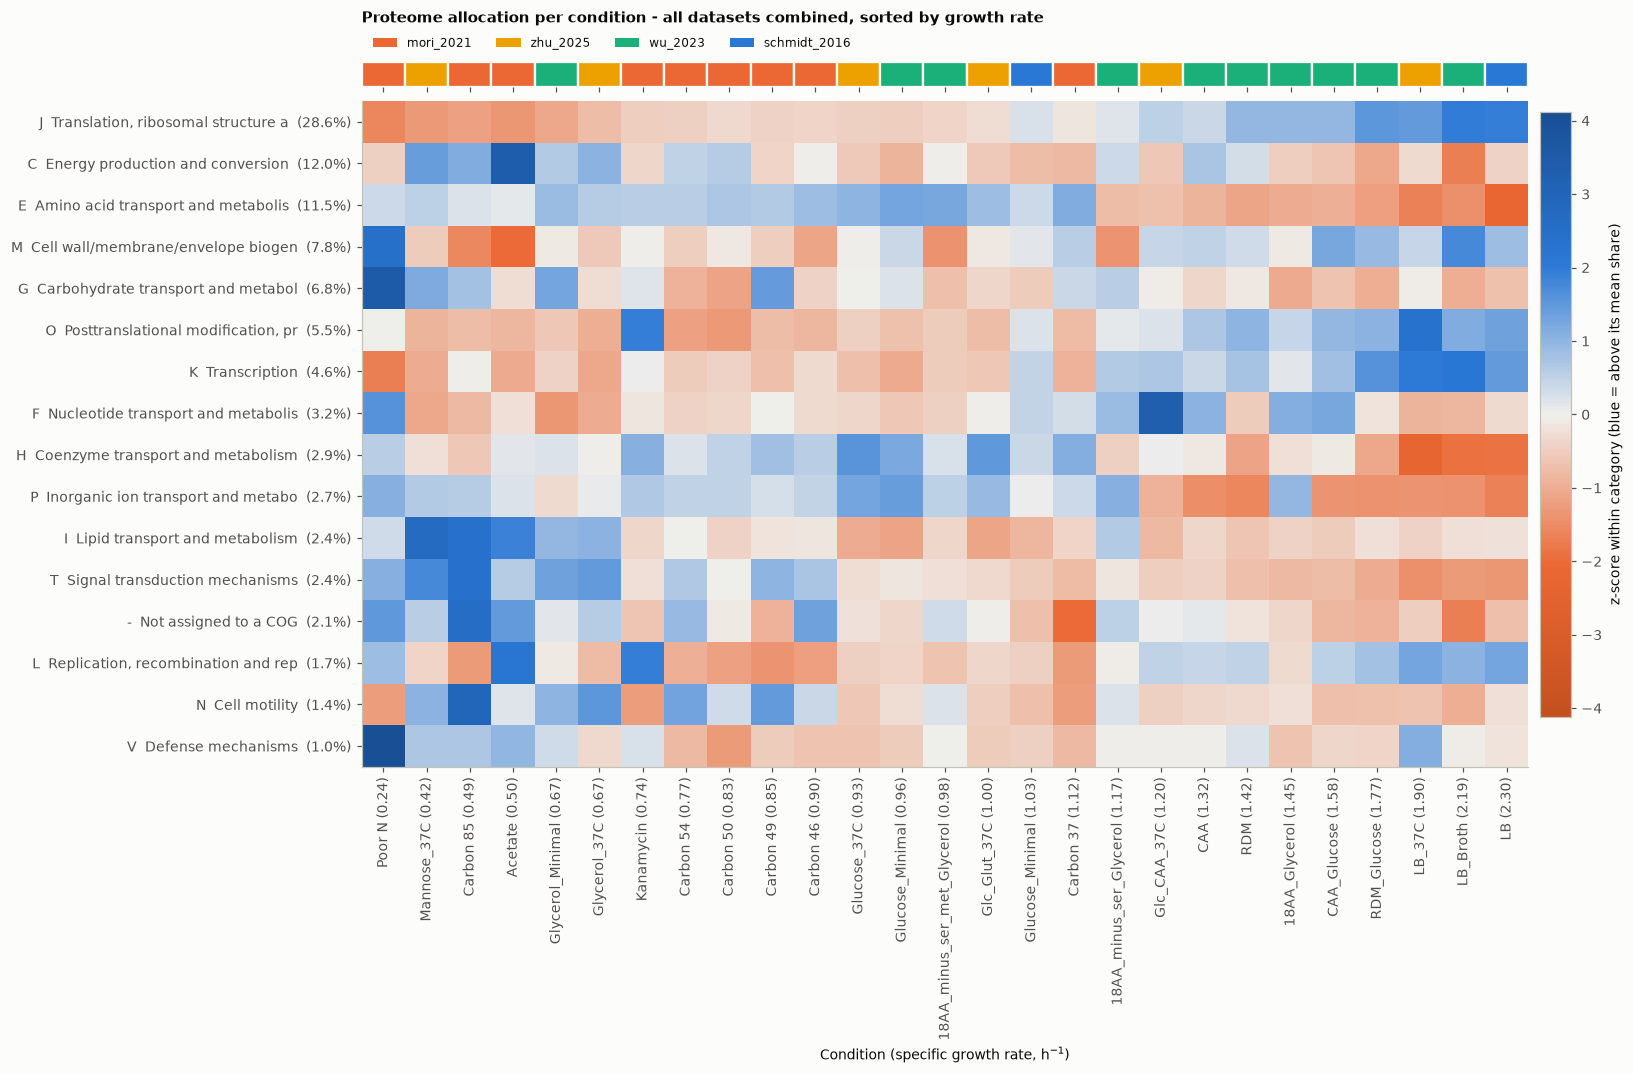

In [6]:
batch_key = cfg["allocation"]["batch_key"]
F_combined = combined.remove_batch_effect(Fc, info, batch_key)
cond_labels = combined.condition_labels(info)

fig = plots.plot_condition_heatmap(F_combined, info, labels, cond_labels, cfg.figures / "03_combined_condition_heatmap.png")
plt.show()

Read the heat map left to right: every column is one growth condition from any of the studies (colour strip = study), ordered from slowest to fastest. Each row is standardised (z-score), so a small category is as visible as the ribosome; its mean share is in brackets. A row going from orange to blue is a category that gains share with growth, blue to orange one that loses share; a column that stands out from its neighbours is a condition-specific response. A diverging scale is used because the values are deviations above or below each category's mean.

The table quantifies the same picture: for each condition, the change of each category in **percentage points of the proteome** relative to the slowest quarter of conditions.

In [7]:
shift = combined.proteome_shift_table(F_combined, info, cond_labels)
main_categories = F_combined.mean().sort_values(ascending=False).index[:10]
order = [cond_labels.loc[i] for i in info.sort_values(GROWTH).index]
display(shift.loc[order, main_categories].rename(columns=lambda c: f"{c} {labels.get(c, '')[:18]}"))

,"J Translation, ribos",C Energy production,E Amino acid transpo,M Cell wall/membrane,G Carbohydrate trans,O Posttranslational,K Transcription,F Nucleotide transpo,H Coenzyme transport,P Inorganic ion tran
Poor N (0.24),-3.50,-3.94,-0.47,3.38,2.56,0.22,-0.43,1.35,0.24,0.65
Mannose_37C (0.42),-1.50,1.20,0.36,-0.24,0.25,-0.40,-0.12,-0.42,-0.24,0.20
Carbon 85 (0.49),-0.59,0.44,-1.30,-1.50,-0.14,-0.32,0.33,-0.26,-0.45,0.18
Acetate (0.50),-1.63,6.64,-1.69,-2.06,-1.14,-0.39,-0.13,0.14,-0.01,-0.20
Glycerol_Minimal (0.67),0.13,-0.92,2.03,0.32,0.34,-0.21,0.14,-0.61,0.03,-0.73
Glycerol_37C (0.67),2.61,0.22,0.59,-0.27,-1.16,-0.48,-0.15,-0.39,-0.11,-0.34
Kanamycin (0.74),4.49,-3.63,0.47,0.37,-0.71,1.58,0.37,0.19,0.54,0.24
Carbon 54 (0.77),4.75,-1.32,0.54,-0.19,-1.78,-0.60,0.09,-0.00,0.02,0.07
Carbon 50 (0.83),5.61,-1.05,1.17,0.25,-1.99,-0.69,0.14,0.05,0.19,0.09
Carbon 49 (0.85),4.90,-3.76,0.73,-0.21,0.50,-0.31,0.01,0.30,0.38,-0.15


## 4 · Growth-rate dependence of each category

In [8]:
table, details = allocation.fit_growth_laws(Fc, info, cfg)
print(details)

shown = ["mean_fraction", "slope_per_h-1", "ci_low", "ci_high", "relative_slope", "within_dataset_R2",
         "p_permutation", "q_BH", "significant", "sign_stable_leave_one_dataset_out"]
tested = table[table["tested"]]
display(tested[shown].assign(description=labels.reindex(tested.index)).round(4))

{'n_conditions': 27, 'conditions_per_dataset': {'wu_2023': 10, 'mori_2021': 9, 'zhu_2025': 6, 'schmidt_2016': 2}, 'n_permutations': 9999, 'n_bootstrap': 4000, 'bootstrap_failed_draws': 0, 'smallest_attainable_p': 0.0001}


,mean_fraction,slope_per_h-1,ci_low,ci_high,relative_slope,within_dataset_R2,p_permutation,q_BH,significant,sign_stable_leave_one_dataset_out,description
COG_Category,,,,,,,,,,,
J,0.2859,0.1386,0.1280,0.1656,0.4849,0.9396,0.0001,0.0005,True,True,"Translation, ribosomal structure and biogenesis"
M,0.0777,0.0104,-0.0015,0.0241,0.1341,0.1331,0.0322,0.0483,True,True,Cell wall/membrane/envelope biogenesis
O,0.0553,0.0094,0.0044,0.0140,0.1696,0.3710,0.0014,0.0048,True,True,"Posttranslational modification, protein turnover, chaper..."
K,0.0463,0.0078,0.0055,0.0105,0.1676,0.6749,0.0001,0.0005,True,True,Transcription
L,0.0168,0.0022,-0.0008,0.0038,0.1289,0.0837,0.1237,0.1528,False,True,"Replication, recombination and repair"
F,0.0320,0.0008,-0.0053,0.0121,0.0260,0.0026,0.8138,0.8138,False,False,Nucleotide transport and metabolism
U,0.0076,0.0006,0.0002,0.0011,0.0842,0.3283,0.0062,0.0145,True,True,"Intracellular trafficking, secretion, and vesicular tran..."
D,0.0068,0.0003,-0.0004,0.0010,0.0510,0.0433,0.2167,0.2395,False,False,"Cell cycle control, cell division, chromosome partitioning"
R,0.0097,-0.0006,-0.0020,0.0004,-0.0575,0.0490,0.2113,0.2395,False,False,General function prediction only


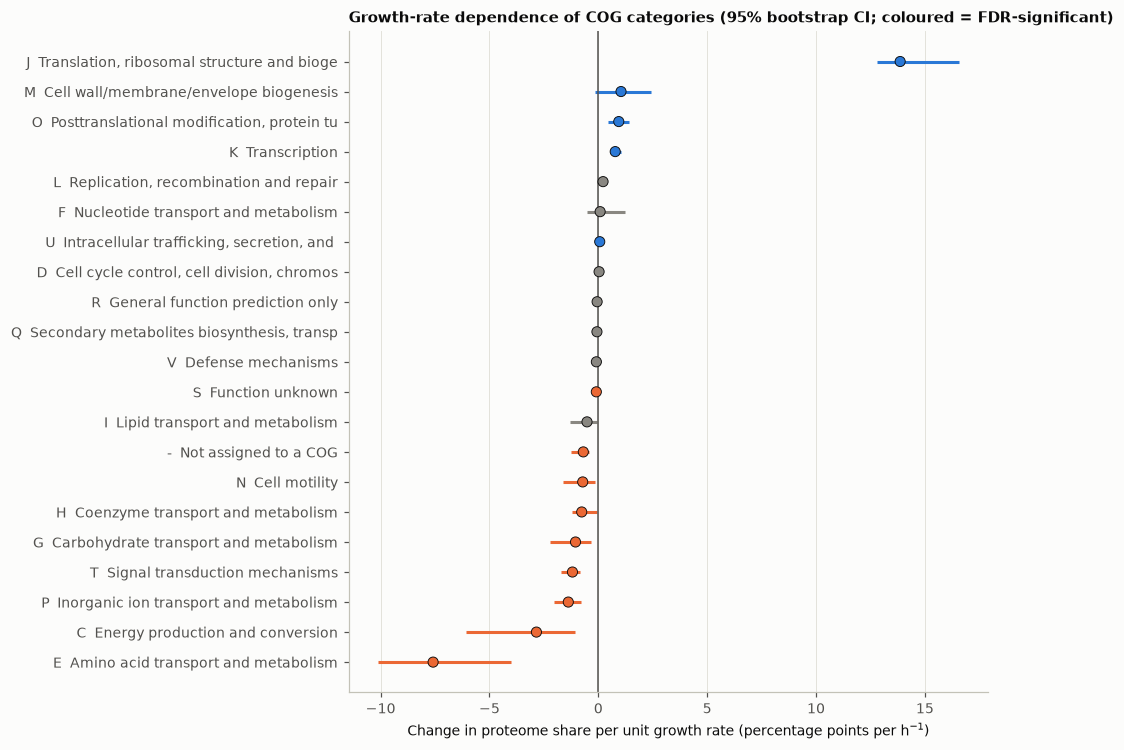

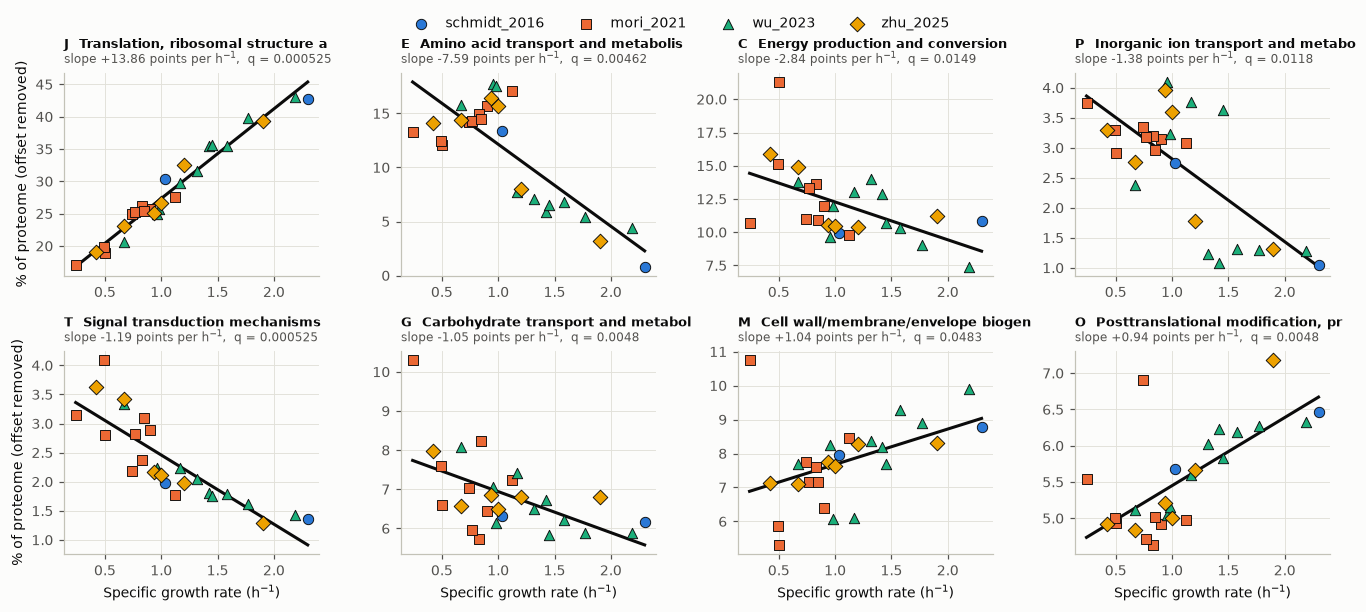

In [9]:
fig = plots.plot_slopes(table, labels, cfg.figures / "03_cog_slopes_forest.png")
plt.show()
fig = plots.plot_combined_growth_laws(F_combined, info, table, labels, cfg.figures / "03_cog_growth_laws_combined.png")
plt.show()

The forest plot shows effect size and uncertainty for every tested category on one axis. The small multiples show the data behind the eight largest effects with **all studies combined**: dataset offsets removed and one line, the shared slope estimated by the model.

The next figure is the same data before offset removal, with one line per batch (same slope, own intercept). It is the honest view of what the model sees and shows whether every study supports the trend.

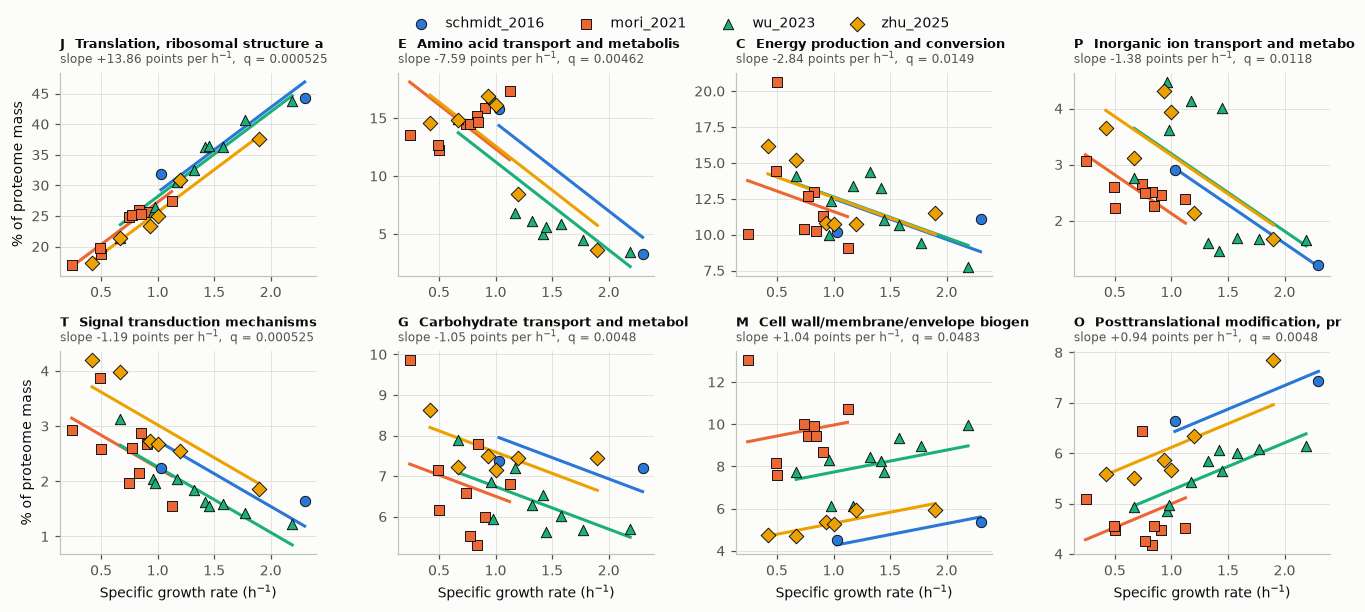

In [10]:
fig = plots.plot_growth_laws(Fc, info, table, labels, cfg.figures / "03_cog_growth_laws_per_batch.png",
                             batch_key=batch_key)
plt.show()

## 5 · Reading the result

* **Slope** is in proteome share per h⁻¹: a slope of +0.10 means the category gains ten percentage points of the proteome when growth rate rises by 1 h⁻¹.
* **Closure.** Fractions sum to 1, so slopes sum to 0. When one large category expands, the others must shrink on average. A negative slope therefore does not by itself show active down-regulation; notebook 04 tests which categories change *more than the rest of the proteome*.
* **Significant and sign-stable** categories are supported by every leave-one-dataset-out fit. A significant category that is not sign-stable depends on one study and should be reported as such.
* The smallest attainable permutation p-value is `1 / (n_permutations + 1)`.

In [11]:
robust = tested[tested["significant"] & tested["sign_stable_leave_one_dataset_out"]]
print(f"Tested categories: {len(tested)} | FDR-significant: {int(tested['significant'].sum())} "
      f"| also sign-stable when any dataset is left out: {len(robust)}")
for category, row in robust.iterrows():
    direction = "rises" if row["slope_per_h-1"] > 0 else "falls"
    print(f"  {category}  {labels.get(category, ''):<58s} {direction} "
          f"{abs(row['slope_per_h-1']) * 100:5.2f} points per h-1 "
          f"[{row['ci_low'] * 100:+.2f}, {row['ci_high'] * 100:+.2f}]")
print(f"Sum of all slopes (must be ~0 because of closure): {table['slope_per_h-1'].sum():+.2e}")

Tested categories: 21 | FDR-significant: 14 | also sign-stable when any dataset is left out: 14
  J  Translation, ribosomal structure and biogenesis            rises 13.86 points per h-1 [+12.80, +16.56]
  M  Cell wall/membrane/envelope biogenesis                     rises  1.04 points per h-1 [-0.15, +2.41]
  O  Posttranslational modification, protein turnover, chaperones rises  0.94 points per h-1 [+0.44, +1.40]
  K  Transcription                                              rises  0.78 points per h-1 [+0.55, +1.05]
  U  Intracellular trafficking, secretion, and vesicular transport rises  0.06 points per h-1 [+0.02, +0.11]
  S  Function unknown                                           falls  0.09 points per h-1 [-0.27, -0.00]
  -  Not assigned to a COG                                      falls  0.69 points per h-1 [-1.24, -0.44]
  N  Cell motility                                              falls  0.72 points per h-1 [-1.63, -0.14]
  H  Coenzyme transport and metabolism           

## 6 · Proteome maps of the two most contrasting conditions

A treemap in the style of *proteomaps* (Liebermeister et al. 2014): each panel is one condition, and every tile's area is its share of the proteome mass. The top row shows COG categories, grouped and coloured by COG super-group (blue: information processing, green: cellular processes, orange/brown: metabolism, grey: poorly characterised or not in COG). The bottom row is the same layout split into individual proteins, labelled with gene names when they are large enough.

**Which two conditions.** Two maps are only comparable if they come from the same measurement batch; otherwise part of the difference would be the platform. The slowest and fastest condition of the batch with the widest growth-rate range are drawn (`proteomap.conditions: auto` in `config.yml`; any pair can be fixed there instead).

Areas are hard to compare by eye, so the bar chart on the right gives the change per category in percentage points. The maps illustrate the reallocation; the evidence that a category depends on growth rate across all studies is the slope analysis above (marked with an asterisk). Each protein is drawn once, in its first COG category, so tile areas can differ slightly from the split-mass fractions used in the statistics.

Conditions drawn: ['wu_2023|Glycerol_Minimal', 'wu_2023|LB_Broth']


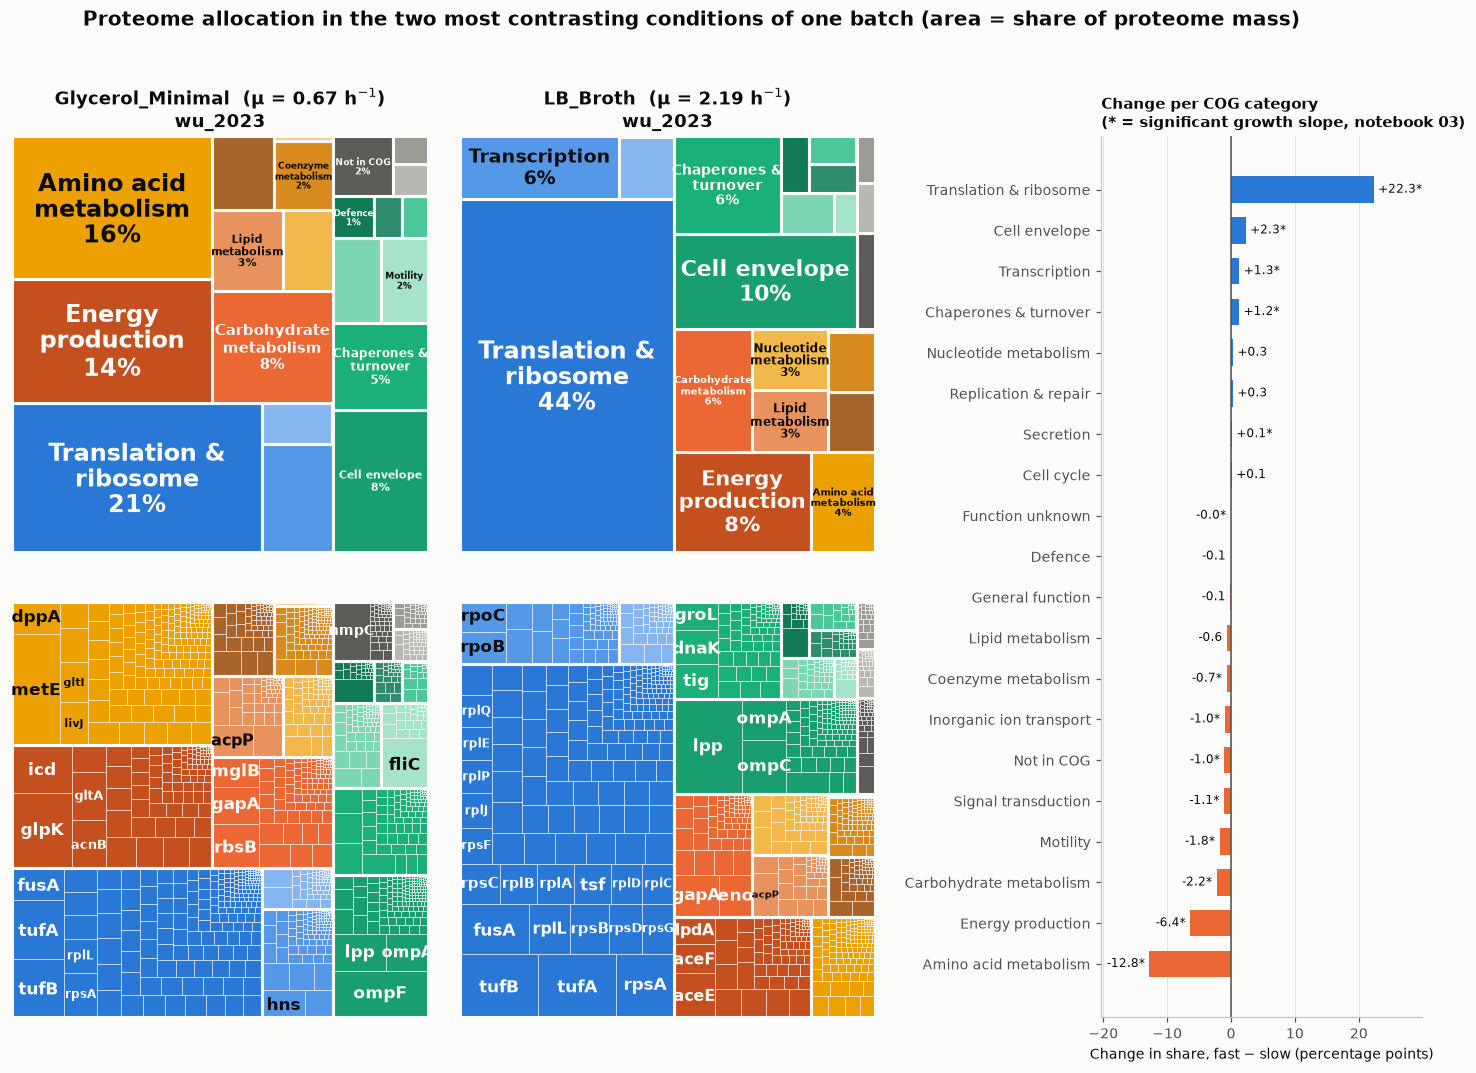

,slow,fast,change_points,description
COG_Categories,,,,
E,16.50,3.74,-12.76,Amino acid metabolism
C,14.29,7.92,-6.38,Energy production
G,7.84,5.59,-2.25,Carbohydrate metabolism
N,2.33,0.53,-1.80,Motility
T,2.36,1.25,-1.10,Signal transduction
-,2.08,1.06,-1.02,Not in COG
P,2.67,1.66,-1.00,Inorganic ion transport
H,2.35,1.65,-0.70,Coenzyme metabolism
I,3.33,2.71,-0.62,Lipid metabolism


In [12]:
protein_profiles, protein_info = proteomap.condition_profiles(X.loc[in_scope], obs.loc[in_scope], cfg)
protein_category = proteomap.primary_category(annotation_table, protein_profiles.columns)
map_conditions = proteomap.select_conditions(protein_info, cfg)
print("Conditions drawn:", map_conditions)

change = proteomap.category_change(protein_profiles, protein_category, map_conditions)
fig = proteomap.plot_proteomaps(protein_profiles, protein_info, protein_category, map_conditions,
                                gene_names=var["Gene_Name"], change=change,
                                significant=table["significant"] & table["sign_stable_leave_one_dataset_out"],
                                path=cfg.figures / "03_proteomaps_contrasting_conditions.png",
                                label_min_share=cfg["proteomap"]["label_min_share"])
plt.show()
display(change.sort_values("change_points").round(2).assign(description=lambda d: [proteomap.SHORT.get(c, c) for c in d.index]))

In [13]:
outputs = [cfg.tables / "03_cog_fractions_per_run.tsv", cfg.tables / "03_cog_fractions_per_condition.tsv",
           cfg.tables / "03_condition_table.tsv", cfg.tables / "03_cog_growth_slopes.tsv",
           cfg.tables / "03_annotation_coverage.tsv", cfg.tables / "03_cog_fractions_combined_display.tsv",
           cfg.tables / "03_proteome_shift_per_condition.tsv", cfg.tables / "03_proteomap_category_change.tsv"]
F.to_csv(outputs[0], sep="\t"); Fc.to_csv(outputs[1], sep="\t"); info.to_csv(outputs[2], sep="\t")
F_combined.to_csv(outputs[5], sep="\t"); shift.to_csv(outputs[6], sep="\t"); change.to_csv(outputs[7], sep="\t")
table.assign(description=labels.reindex(table.index)).to_csv(outputs[3], sep="\t"); coverage.to_csv(outputs[4], sep="\t")

config.log_run(cfg, "03_cog_allocation_vs_growth",
               params={"allocation": cfg["allocation"], "multi_category": cfg["annotation"]["multi_category"],
                       "proteomap": {**cfg["proteomap"], "conditions_drawn": map_conditions}},
               outputs=outputs, notes=details)
print("Tables written to", cfg.tables.relative_to(cfg.root))

Tables written to results\tables
